In [1]:
import warnings, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, cohen_kappa_score,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, auc)
from sklearn.preprocessing import label_binarize

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              AdaBoostClassifier, BaggingClassifier, HistGradientBoostingClassifier)
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

## 1. Load & inspect the data

In [2]:
path = "liver_cirrhosis_dataset.csv"
if not os.path.exists(path):
    path = "/content/liver_cirrhosis_dataset.csv"

# keep_default_na=False: the string "None" in Alcohol_Consumption is a real category (no alcohol),
# not a missing value. Pandas would otherwise silently turn it into NaN.
df = pd.read_csv(path, keep_default_na=False, na_values=[""])
print("Shape:", df.shape)
df.head()

Shape: (100, 37)


,Patient_ID,Age,Gender,BMI,Alcohol_Consumption,Smoking_Status,Hepatitis_B,Hepatitis_C,Diabetes,Hypertension,Family_History,Albumin,Bilirubin,Prothrombin_Time,Platelet_Count,AST,ALT,ALP,GGT,Sodium,Creatinine,INR,Copper,Triglycerides,Cholesterol,Ascites,Hepatic_Encephalopathy,Varices,Spider_Angiomas,Edema,Fatigue_Score,Jaundice,Spleen_Size,Fibrosis_Stage,MELD_Score,Child_Pugh_Class,Cirrhosis_Status
0,LC001,58,Male,28.4,Heavy,Former,0,1,0,1,1,3.2,2.8,14.5,145,78,65,125,98,138,1.2,1.3,85,175,210,1,0,1,1,1,7,1,Enlarged,F4,18,B,Decompensated
1,LC002,42,Female,24.1,None,Never,0,0,1,0,0,4.2,0.8,11.2,285,32,28,85,42,140,0.9,1.0,45,120,185,0,0,0,0,0,2,0,Normal,F0,6,A,No_Cirrhosis
2,LC003,65,Male,31.2,Moderate,Current,1,0,1,1,0,2.8,4.2,16.8,95,156,142,245,165,134,1.8,1.6,125,230,255,1,1,1,1,1,9,1,Enlarged,F4,24,C,Decompensated
3,LC004,55,Male,26.8,Heavy,Former,0,1,0,1,1,3.5,1.9,13.2,165,68,58,112,78,139,1.1,1.2,72,145,198,0,0,1,1,0,5,0,Mild,F3,14,B,Compensated
4,LC005,38,Female,22.5,Light,Never,0,0,0,0,0,4.5,0.6,10.8,310,25,22,72,35,142,0.7,0.9,38,95,165,0,0,0,0,0,1,0,Normal,F0,4,A,No_Cirrhosis


In [3]:
df.info()
print("\nMissing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum(), "| Duplicate Patient_IDs:", df["Patient_ID"].duplicated().sum())
print("\nAlcohol_Consumption values:", df["Alcohol_Consumption"].value_counts().to_dict())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 37 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Patient_ID              100 non-null    object 
 1   Age                     100 non-null    int64  
 2   Gender                  100 non-null    object 
 3   BMI                     100 non-null    float64
 4   Alcohol_Consumption     100 non-null    object 
 5   Smoking_Status          100 non-null    object 
 6   Hepatitis_B             100 non-null    int64  
 7   Hepatitis_C             100 non-null    int64  
 8   Diabetes                100 non-null    int64  
 9   Hypertension            100 non-null    int64  
 10  Family_History          100 non-null    int64  
 11  Albumin                 100 non-null    float64
 12  Bilirubin               100 non-null    float64
 13  Prothrombin_Time        100 non-null    float64
 14  Platelet_Count          100 non-null    int

**Finding:** there are no true missing values. The 24 "missing" entries in `Alcohol_Consumption` that a default `read_csv` shows are the literal category `"None"` (patients who do not drink) — a classic pandas pitfall — so they are preserved here.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,100.0,54.720,11.693977,32.0,45.750,55.00,64.250,75.0
BMI,100.0,27.989,3.720972,20.5,25.200,28.20,31.000,34.5
Hepatitis_B,100.0,0.240,0.429235,0.0,0.000,0.00,0.000,1.0
Hepatitis_C,100.0,0.380,0.487832,0.0,0.000,0.00,1.000,1.0
Diabetes,100.0,0.390,0.490207,0.0,0.000,0.00,1.000,1.0
Hypertension,100.0,0.520,0.502117,0.0,0.000,1.00,1.000,1.0
Family_History,100.0,0.410,0.494311,0.0,0.000,0.00,1.000,1.0
Albumin,100.0,3.414,0.808293,2.0,2.675,3.45,4.125,4.7
Bilirubin,100.0,2.708,2.088481,0.4,0.875,1.95,4.525,7.2
Prothrombin_Time,100.0,14.174,3.001165,10.2,11.425,13.50,16.850,20.5


## 2. Exploratory data analysis

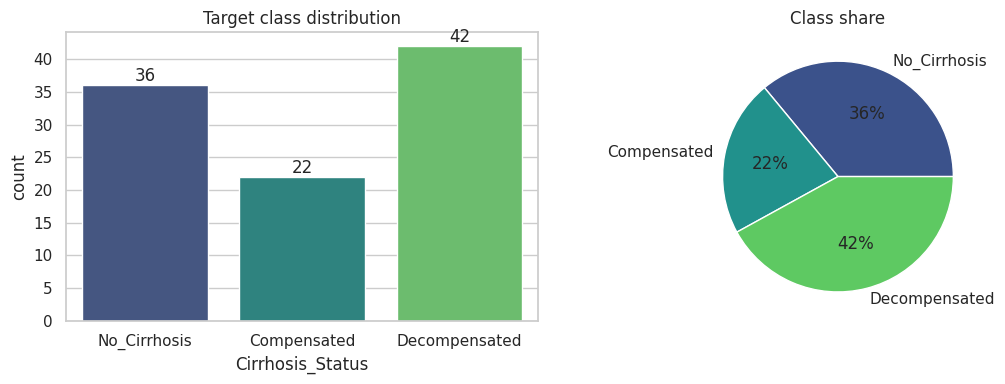

In [5]:
order = ["No_Cirrhosis", "Compensated", "Decompensated"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="Cirrhosis_Status", order=order, palette="viridis", ax=ax[0])
ax[0].set_title("Target class distribution")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
df["Cirrhosis_Status"].value_counts().reindex(order).plot.pie(autopct="%1.0f%%", ax=ax[1], colors=sns.color_palette("viridis", 3))
ax[1].set_ylabel(""); ax[1].set_title("Class share")
plt.tight_layout(); plt.show()

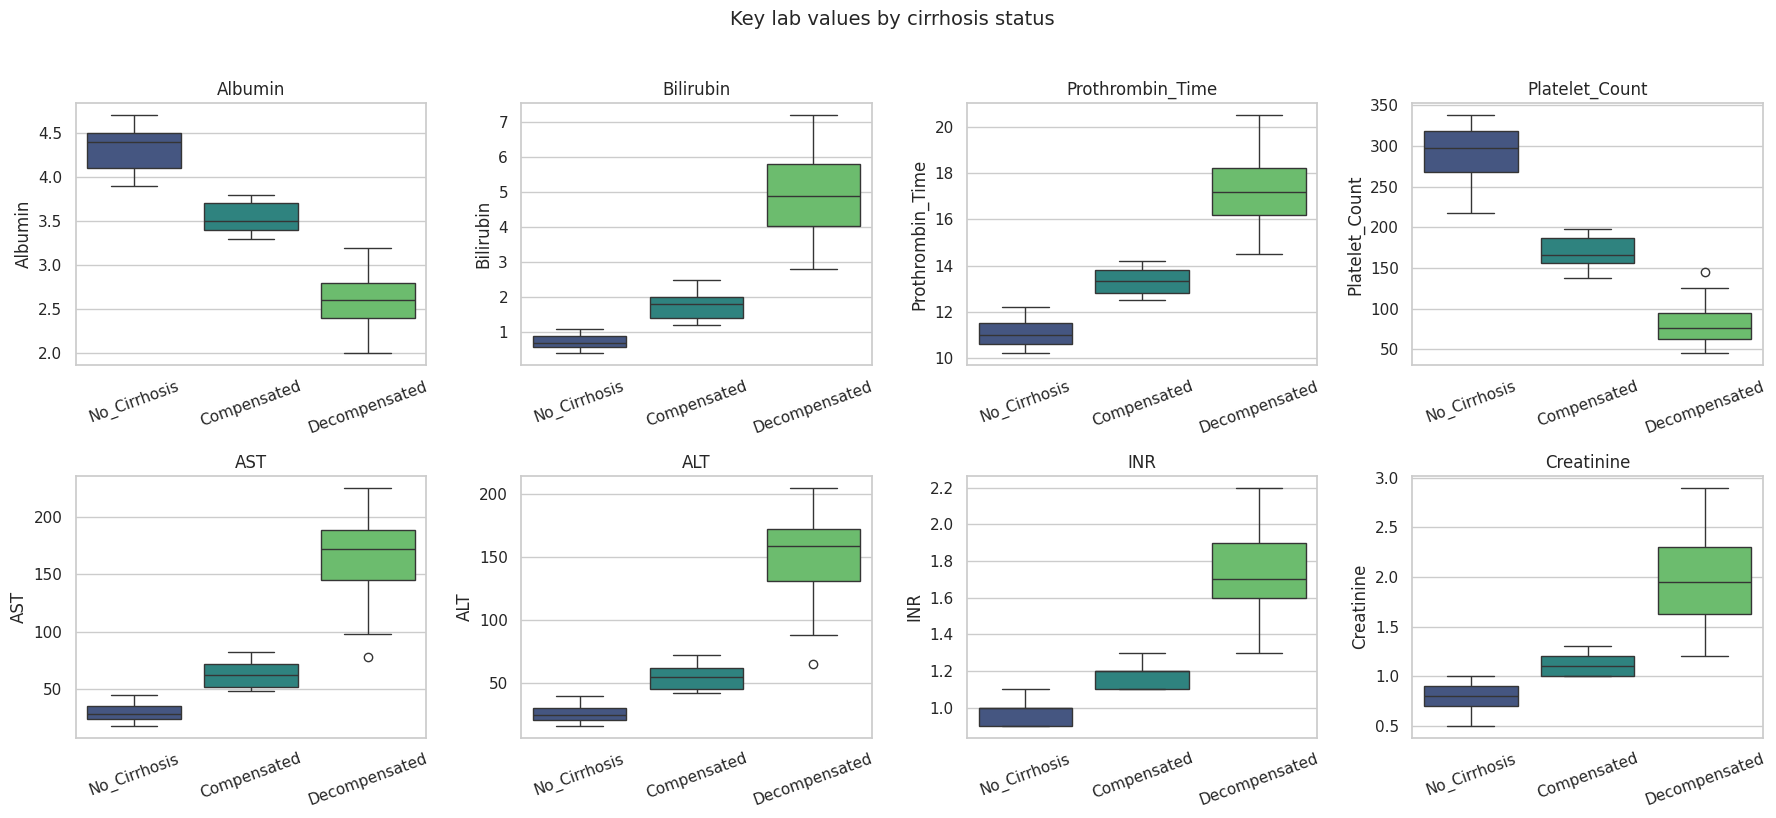

In [6]:
key_labs = ["Albumin","Bilirubin","Prothrombin_Time","Platelet_Count","AST","ALT","INR","Creatinine"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for a, c in zip(axes.ravel(), key_labs):
    sns.boxplot(data=df, x="Cirrhosis_Status", y=c, order=order, palette="viridis", ax=a)
    a.set_xlabel(""); a.tick_params(axis="x", rotation=20); a.set_title(c)
plt.suptitle("Key lab values by cirrhosis status", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

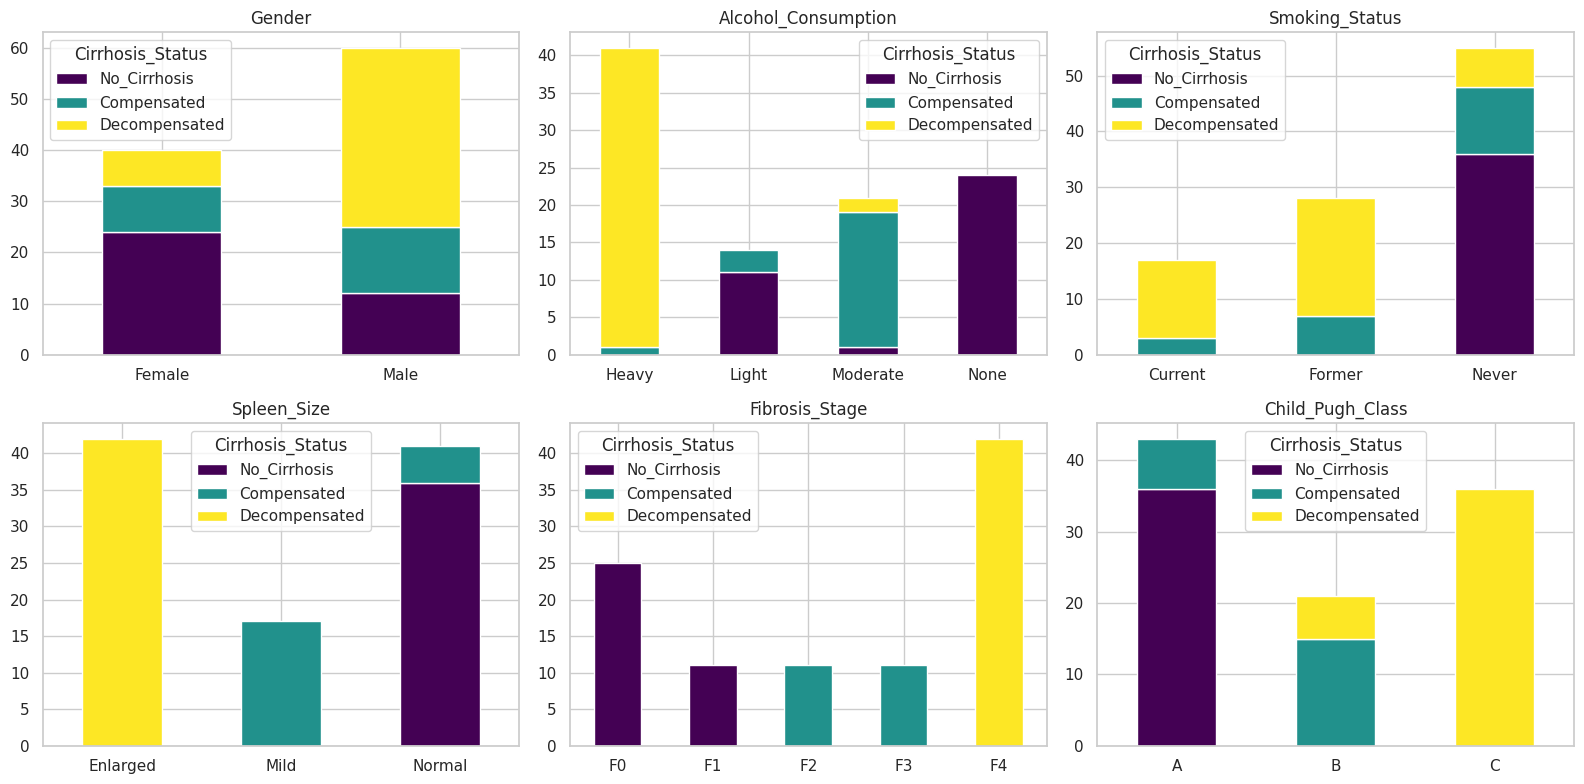

In [7]:
cat_cols = ["Gender","Alcohol_Consumption","Smoking_Status","Spleen_Size","Fibrosis_Stage","Child_Pugh_Class"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for a, c in zip(axes.ravel(), cat_cols):
    pd.crosstab(df[c], df["Cirrhosis_Status"])[order].plot.bar(stacked=True, ax=a, colormap="viridis")
    a.set_title(c); a.set_xlabel(""); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 3. Data preprocessing

Steps:
1. **Drop `Patient_ID`** — an identifier with no predictive meaning.
2. **Encode ordinal categoricals** with their natural clinical order (alcohol: None < Light < Moderate < Heavy; smoking: Never < Former < Current; spleen: Normal < Mild < Enlarged; fibrosis F0–F4; Child-Pugh A–C).
3. **Encode `Gender`** as binary.
4. **Label-encode the target** (0 = No_Cirrhosis, 1 = Compensated, 2 = Decompensated).
5. **Leakage check** (below), then **stratified train/test split**.
6. **Standardise** numeric features *inside each pipeline* (fit on training folds only) — important for distance/margin-based models (KNN, SVM, LR, MLP).

In [8]:
data = df.drop(columns=["Patient_ID"]).copy()

ordinal_maps = {
    "Alcohol_Consumption": {"None": 0, "Light": 1, "Moderate": 2, "Heavy": 3},
    "Smoking_Status":      {"Never": 0, "Former": 1, "Current": 2},
    "Spleen_Size":         {"Normal": 0, "Mild": 1, "Enlarged": 2},
    "Fibrosis_Stage":      {"F0": 0, "F1": 1, "F2": 2, "F3": 3, "F4": 4},
    "Child_Pugh_Class":    {"A": 0, "B": 1, "C": 2},
    "Gender":              {"Female": 0, "Male": 1},
}
for col, mapping in ordinal_maps.items():
    data[col] = data[col].map(mapping)
assert data.isna().sum().sum() == 0, "Unmapped category found"

target_map = {"No_Cirrhosis": 0, "Compensated": 1, "Decompensated": 2}
class_names = list(target_map.keys())
data["Cirrhosis_Status"] = data["Cirrhosis_Status"].map(target_map)
data.head()

,Age,Gender,BMI,Alcohol_Consumption,Smoking_Status,Hepatitis_B,Hepatitis_C,Diabetes,Hypertension,Family_History,Albumin,Bilirubin,Prothrombin_Time,Platelet_Count,AST,ALT,ALP,GGT,Sodium,Creatinine,INR,Copper,Triglycerides,Cholesterol,Ascites,Hepatic_Encephalopathy,Varices,Spider_Angiomas,Edema,Fatigue_Score,Jaundice,Spleen_Size,Fibrosis_Stage,MELD_Score,Child_Pugh_Class,Cirrhosis_Status
0,58,1,28.4,3,1,0,1,0,1,1,3.2,2.8,14.5,145,78,65,125,98,138,1.2,1.3,85,175,210,1,0,1,1,1,7,1,2,4,18,1,2
1,42,0,24.1,0,0,0,0,1,0,0,4.2,0.8,11.2,285,32,28,85,42,140,0.9,1.0,45,120,185,0,0,0,0,0,2,0,0,0,6,0,0
2,65,1,31.2,2,2,1,0,1,1,0,2.8,4.2,16.8,95,156,142,245,165,134,1.8,1.6,125,230,255,1,1,1,1,1,9,1,2,4,24,2,2
3,55,1,26.8,3,1,0,1,0,1,1,3.5,1.9,13.2,165,68,58,112,78,139,1.1,1.2,72,145,198,0,0,1,1,0,5,0,1,3,14,1,1
4,38,0,22.5,1,0,0,0,0,0,0,4.5,0.6,10.8,310,25,22,72,35,142,0.7,0.9,38,95,165,0,0,0,0,0,1,0,0,0,4,0,0


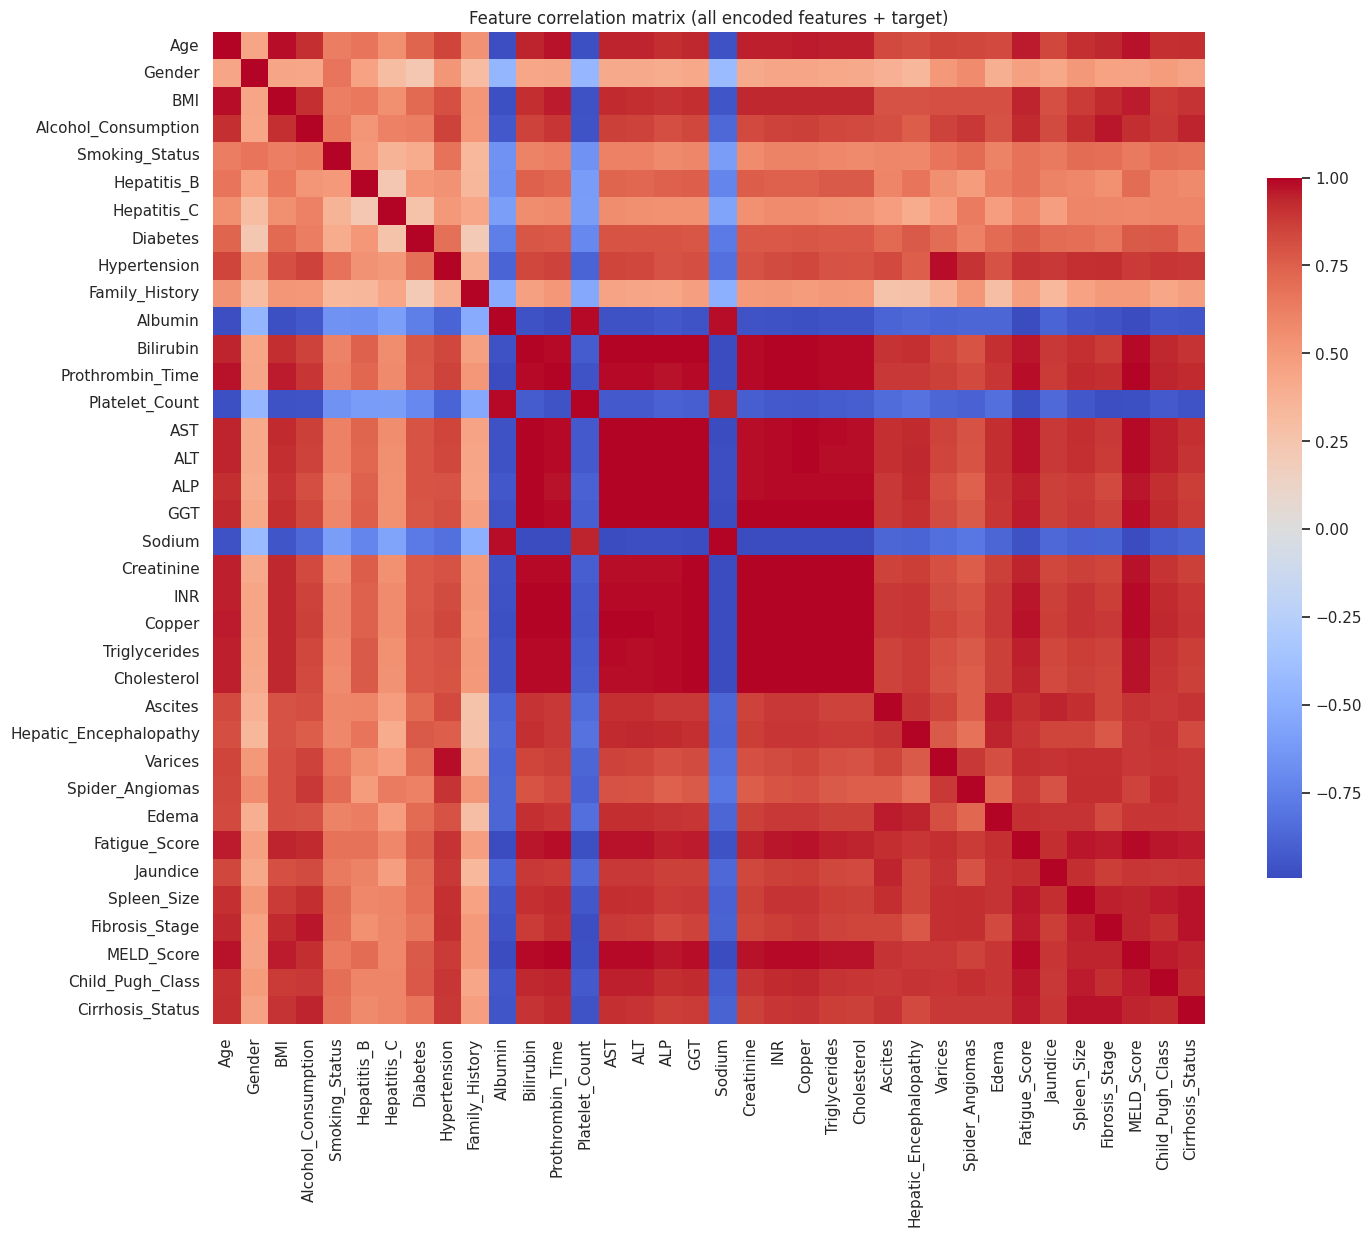

Strongest correlations with target:
Fibrosis_Stage         0.972
Spleen_Size            0.971
Platelet_Count         0.960
Fatigue_Score          0.959
Albumin                0.949
MELD_Score             0.943
Alcohol_Consumption    0.940
Child_Pugh_Class       0.928
Prothrombin_Time       0.928
Age                    0.917
Name: Cirrhosis_Status, dtype: float64


In [9]:
plt.figure(figsize=(16, 13))
corr = data.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True, cbar_kws={"shrink": .7})
plt.title("Feature correlation matrix (all encoded features + target)")
plt.show()

print("Strongest correlations with target:")
print(corr["Cirrhosis_Status"].drop("Cirrhosis_Status").abs().sort_values(ascending=False).head(10).round(3))

### Leakage check

`Fibrosis_Stage`, `MELD_Score` and `Child_Pugh_Class` are **disease-severity scores that are assessed after (or alongside) a cirrhosis diagnosis**. They correlate almost perfectly with the target (e.g. every F4 patient is Decompensated, every F0/F1 patient is No_Cirrhosis), so a model using them is partly "re-reading" the diagnosis rather than predicting it. Let's look at that:

In [10]:
severity = ["Fibrosis_Stage", "MELD_Score", "Child_Pugh_Class"]
print(pd.crosstab(df["Fibrosis_Stage"], df["Cirrhosis_Status"])[order], "\n")
print(pd.crosstab(df["Child_Pugh_Class"], df["Cirrhosis_Status"])[order])

Cirrhosis_Status  No_Cirrhosis  Compensated  Decompensated
Fibrosis_Stage                                            
F0                          25            0              0
F1                          11            0              0
F2                           0           11              0
F3                           0           11              0
F4                           0            0             42 

Cirrhosis_Status  No_Cirrhosis  Compensated  Decompensated
Child_Pugh_Class                                          
A                           36            7              0
B                            0           15              6
C                            0            0             36


**Decision:** the **main experiment (Scenario A)** predicts cirrhosis from *demographics, lifestyle, labs, symptoms and spleen size only* (no severity scores) — the realistic screening use-case. **Scenario B** (Section 8) adds the severity scores back to measure how much they actually change the results.

In [11]:
y = data["Cirrhosis_Status"]
FEATURES_A = [c for c in data.columns if c not in severity + ["Cirrhosis_Status"]]
FEATURES_B = [c for c in data.columns if c != "Cirrhosis_Status"]
print(f"Scenario A: {len(FEATURES_A)} features | Scenario B: {len(FEATURES_B)} features")

X_train, X_test, y_train, y_test = train_test_split(
    data[FEATURES_B], y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train class counts:", y_train.value_counts().sort_index().tolist(),
      "| Test class counts:", y_test.value_counts().sort_index().tolist())

Scenario A: 32 features | Scenario B: 35 features
Train: (80, 35) | Test: (20, 35)
Train class counts: [29, 17, 34] | Test class counts: [7, 5, 8]


## 4. Model definitions (13 classifiers)

Each model sits in a `Pipeline` with a `StandardScaler`, so scaling statistics are learned from training data only (no leakage into validation folds). Class imbalance is mild (42/36/22), handled with `class_weight="balanced"` where supported.

In [12]:
def make_models():
    return {
        "Logistic Regression":  LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE),
        "KNN":                  KNeighborsClassifier(n_neighbors=5),
        "SVM (RBF)":            SVC(kernel="rbf", C=1.0, probability=True, class_weight="balanced", random_state=RANDOM_STATE),
        "Decision Tree":        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        "Random Forest":        RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
        "Extra Trees":          ExtraTreesClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE),
        "Gradient Boosting":    GradientBoostingClassifier(random_state=RANDOM_STATE),
        "HistGradient Boosting":HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        "AdaBoost":             AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
        "Bagging":              BaggingClassifier(n_estimators=100, random_state=RANDOM_STATE),
        "Gaussian Naive Bayes": GaussianNB(),
        "LDA":                  LinearDiscriminantAnalysis(),
        "MLP Neural Network":   MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=3000, random_state=RANDOM_STATE),
    }

def make_pipelines():
    return {name: Pipeline([("scaler", StandardScaler()), ("clf", m)]) for name, m in make_models().items()}

print(len(make_models()), "models:", ", ".join(make_models()))

13 models: Logistic Regression, KNN, SVM (RBF), Decision Tree, Random Forest, Extra Trees, Gradient Boosting, HistGradient Boosting, AdaBoost, Bagging, Gaussian Naive Bayes, LDA, MLP Neural Network


## 5. Evaluation framework

Two complementary evaluations are run for every model:

* **Repeated stratified 5-fold CV (×5 repeats = 25 fits)** on the training set → mean ± std of accuracy, macro precision/recall/F1, and ROC-AUC. Most reliable with so little data.
* **Hold-out test set (20 patients)** → accuracy, balanced accuracy, macro & weighted precision/recall/F1, ROC-AUC (OvR), MCC, Cohen's κ.

Macro averaging treats the three classes equally, which matters because *Compensated* is the minority class.

In [13]:
def run_experiment(features, label, n_repeats=5):
    Xtr, Xte = X_train[features], X_test[features]
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=RANDOM_STATE)
    scoring = {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro",
               "f1": "f1_macro", "roc_auc": "roc_auc_ovr"}
    cv_rows, test_rows, fitted, probas, preds = [], [], {}, {}, {}

    for name, pipe in make_pipelines().items():
        # ---- cross-validation on training data
        cvr = cross_validate(pipe, Xtr, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        cv_rows.append({"Model": name, **{f"CV {k}": cvr[f"test_{k}"].mean() for k in scoring},
                        "CV accuracy std": cvr["test_accuracy"].std(), "CV f1 std": cvr["test_f1"].std()})
        # ---- fit on full train set, score on hold-out
        pipe.fit(Xtr, y_train)
        yp, pr = pipe.predict(Xte), pipe.predict_proba(Xte)
        fitted[name], probas[name], preds[name] = pipe, pr, yp
        test_rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, yp),
            "Balanced Acc": balanced_accuracy_score(y_test, yp),
            "Precision (macro)": precision_score(y_test, yp, average="macro", zero_division=0),
            "Recall (macro)": recall_score(y_test, yp, average="macro", zero_division=0),
            "F1 (macro)": f1_score(y_test, yp, average="macro", zero_division=0),
            "Precision (weighted)": precision_score(y_test, yp, average="weighted", zero_division=0),
            "Recall (weighted)": recall_score(y_test, yp, average="weighted", zero_division=0),
            "F1 (weighted)": f1_score(y_test, yp, average="weighted", zero_division=0),
            "ROC-AUC (OvR)": roc_auc_score(y_test, pr, multi_class="ovr", average="macro"),
            "MCC": matthews_corrcoef(y_test, yp),
            "Cohen Kappa": cohen_kappa_score(y_test, yp),
        })
    cv_df = pd.DataFrame(cv_rows).set_index("Model").sort_values("CV f1", ascending=False)
    test_df = pd.DataFrame(test_rows).set_index("Model").loc[cv_df.index]
    return dict(cv=cv_df, test=test_df, fitted=fitted, probas=probas, preds=preds, features=features, label=label)

resA = run_experiment(FEATURES_A, "Scenario A (no severity scores)")
print("Done —", len(resA["fitted"]), "models evaluated.")

Done — 13 models evaluated.


## 6. Results — Scenario A (no severity scores)

### 6.1 Cross-validation performance (mean over 25 folds, sorted by macro-F1)

In [14]:
resA["cv"].round(4).style.background_gradient(cmap="YlGn", subset=["CV accuracy","CV precision","CV recall","CV f1","CV roc_auc"]).format("{:.4f}")

,CV accuracy,CV precision,CV recall,CV f1,CV roc_auc,CV accuracy std,CV f1 std
Model,,,,,,,
Extra Trees,0.9975,0.9967,0.9978,0.9969,1.0000,0.0122,0.0153
Random Forest,0.9900,0.9873,0.9924,0.9887,1.0000,0.0229,0.0260
AdaBoost,0.9900,0.9907,0.9881,0.9880,1.0000,0.0229,0.0276
Bagging,0.9875,0.9853,0.9902,0.9861,1.0000,0.0306,0.0342
Gradient Boosting,0.9825,0.9833,0.9787,0.9785,1.0000,0.0281,0.0347
HistGradient Boosting,0.9775,0.9840,0.9729,0.9735,0.9980,0.0556,0.0612
Decision Tree,0.9650,0.9650,0.9602,0.9593,0.9714,0.0533,0.0604
Logistic Regression,0.9550,0.9528,0.9484,0.9432,0.9970,0.0516,0.0681
MLP Neural Network,0.9475,0.9454,0.9373,0.9346,0.9951,0.0550,0.0669


### 6.2 Hold-out test performance

In [15]:
resA["test"].round(4).style.background_gradient(cmap="YlGn").format("{:.4f}")

,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (OvR),MCC,Cohen Kappa
Model,,,,,,,,,,,
Extra Trees,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
AdaBoost,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,1.0000,0.9265,0.9228
Bagging,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
HistGradient Boosting,0.9000,0.8667,0.9333,0.8667,0.8796,0.9200,0.9000,0.8931,1.0000,0.8578,0.8438
Decision Tree,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,0.9528,0.9265,0.9228
Logistic Regression,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,0.9956,0.9265,0.9228
MLP Neural Network,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,1.0000,0.9265,0.9228


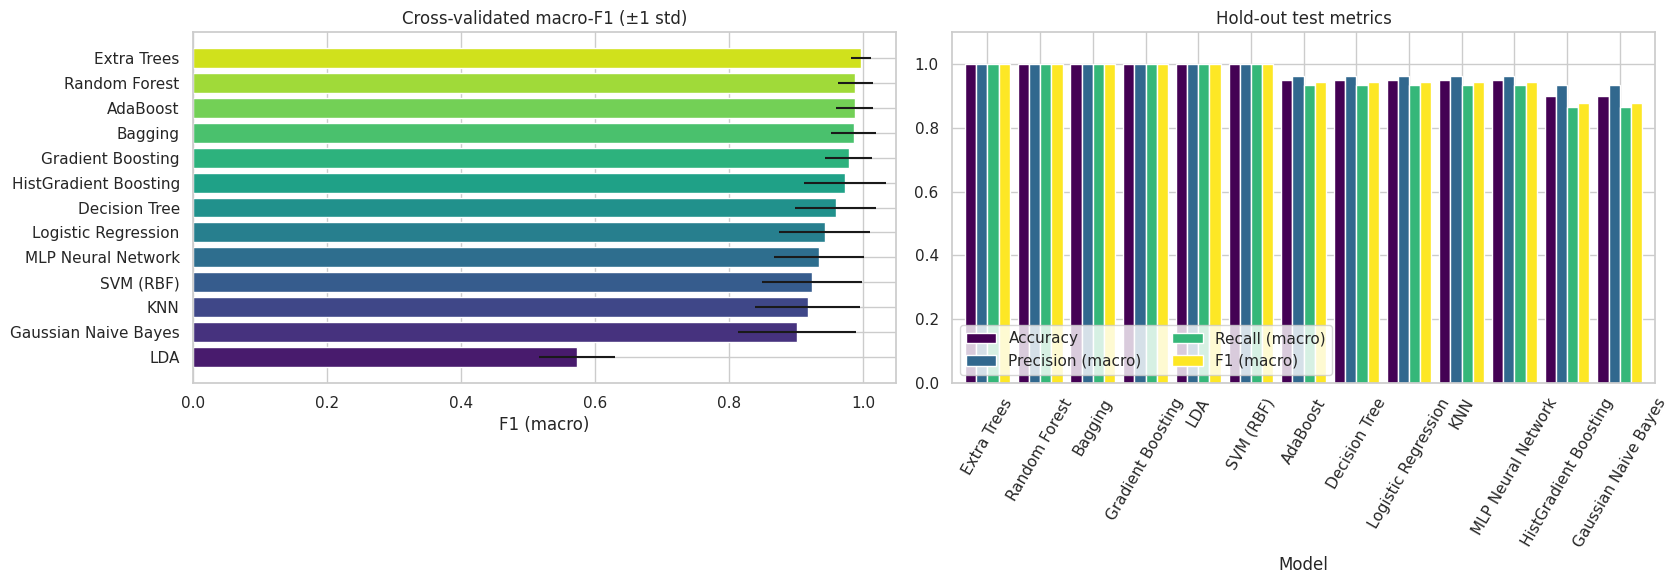

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
cvd = resA["cv"].sort_values("CV f1")
ax[0].barh(cvd.index, cvd["CV f1"], xerr=cvd["CV f1 std"], color=sns.color_palette("viridis", len(cvd)))
ax[0].set_xlim(0.0, 1.05); ax[0].set_title("Cross-validated macro-F1 (±1 std)"); ax[0].set_xlabel("F1 (macro)")

m = resA["test"][["Accuracy","Precision (macro)","Recall (macro)","F1 (macro)"]].sort_values("F1 (macro)", ascending=False)
m.plot.bar(ax=ax[1], width=0.85, colormap="viridis"); ax[1].set_ylim(0, 1.1)
ax[1].set_title("Hold-out test metrics"); ax[1].tick_params(axis="x", rotation=60); ax[1].legend(loc="lower left", ncol=2)
plt.tight_layout(); plt.show()

### 6.3 Confusion matrices (hold-out test set)

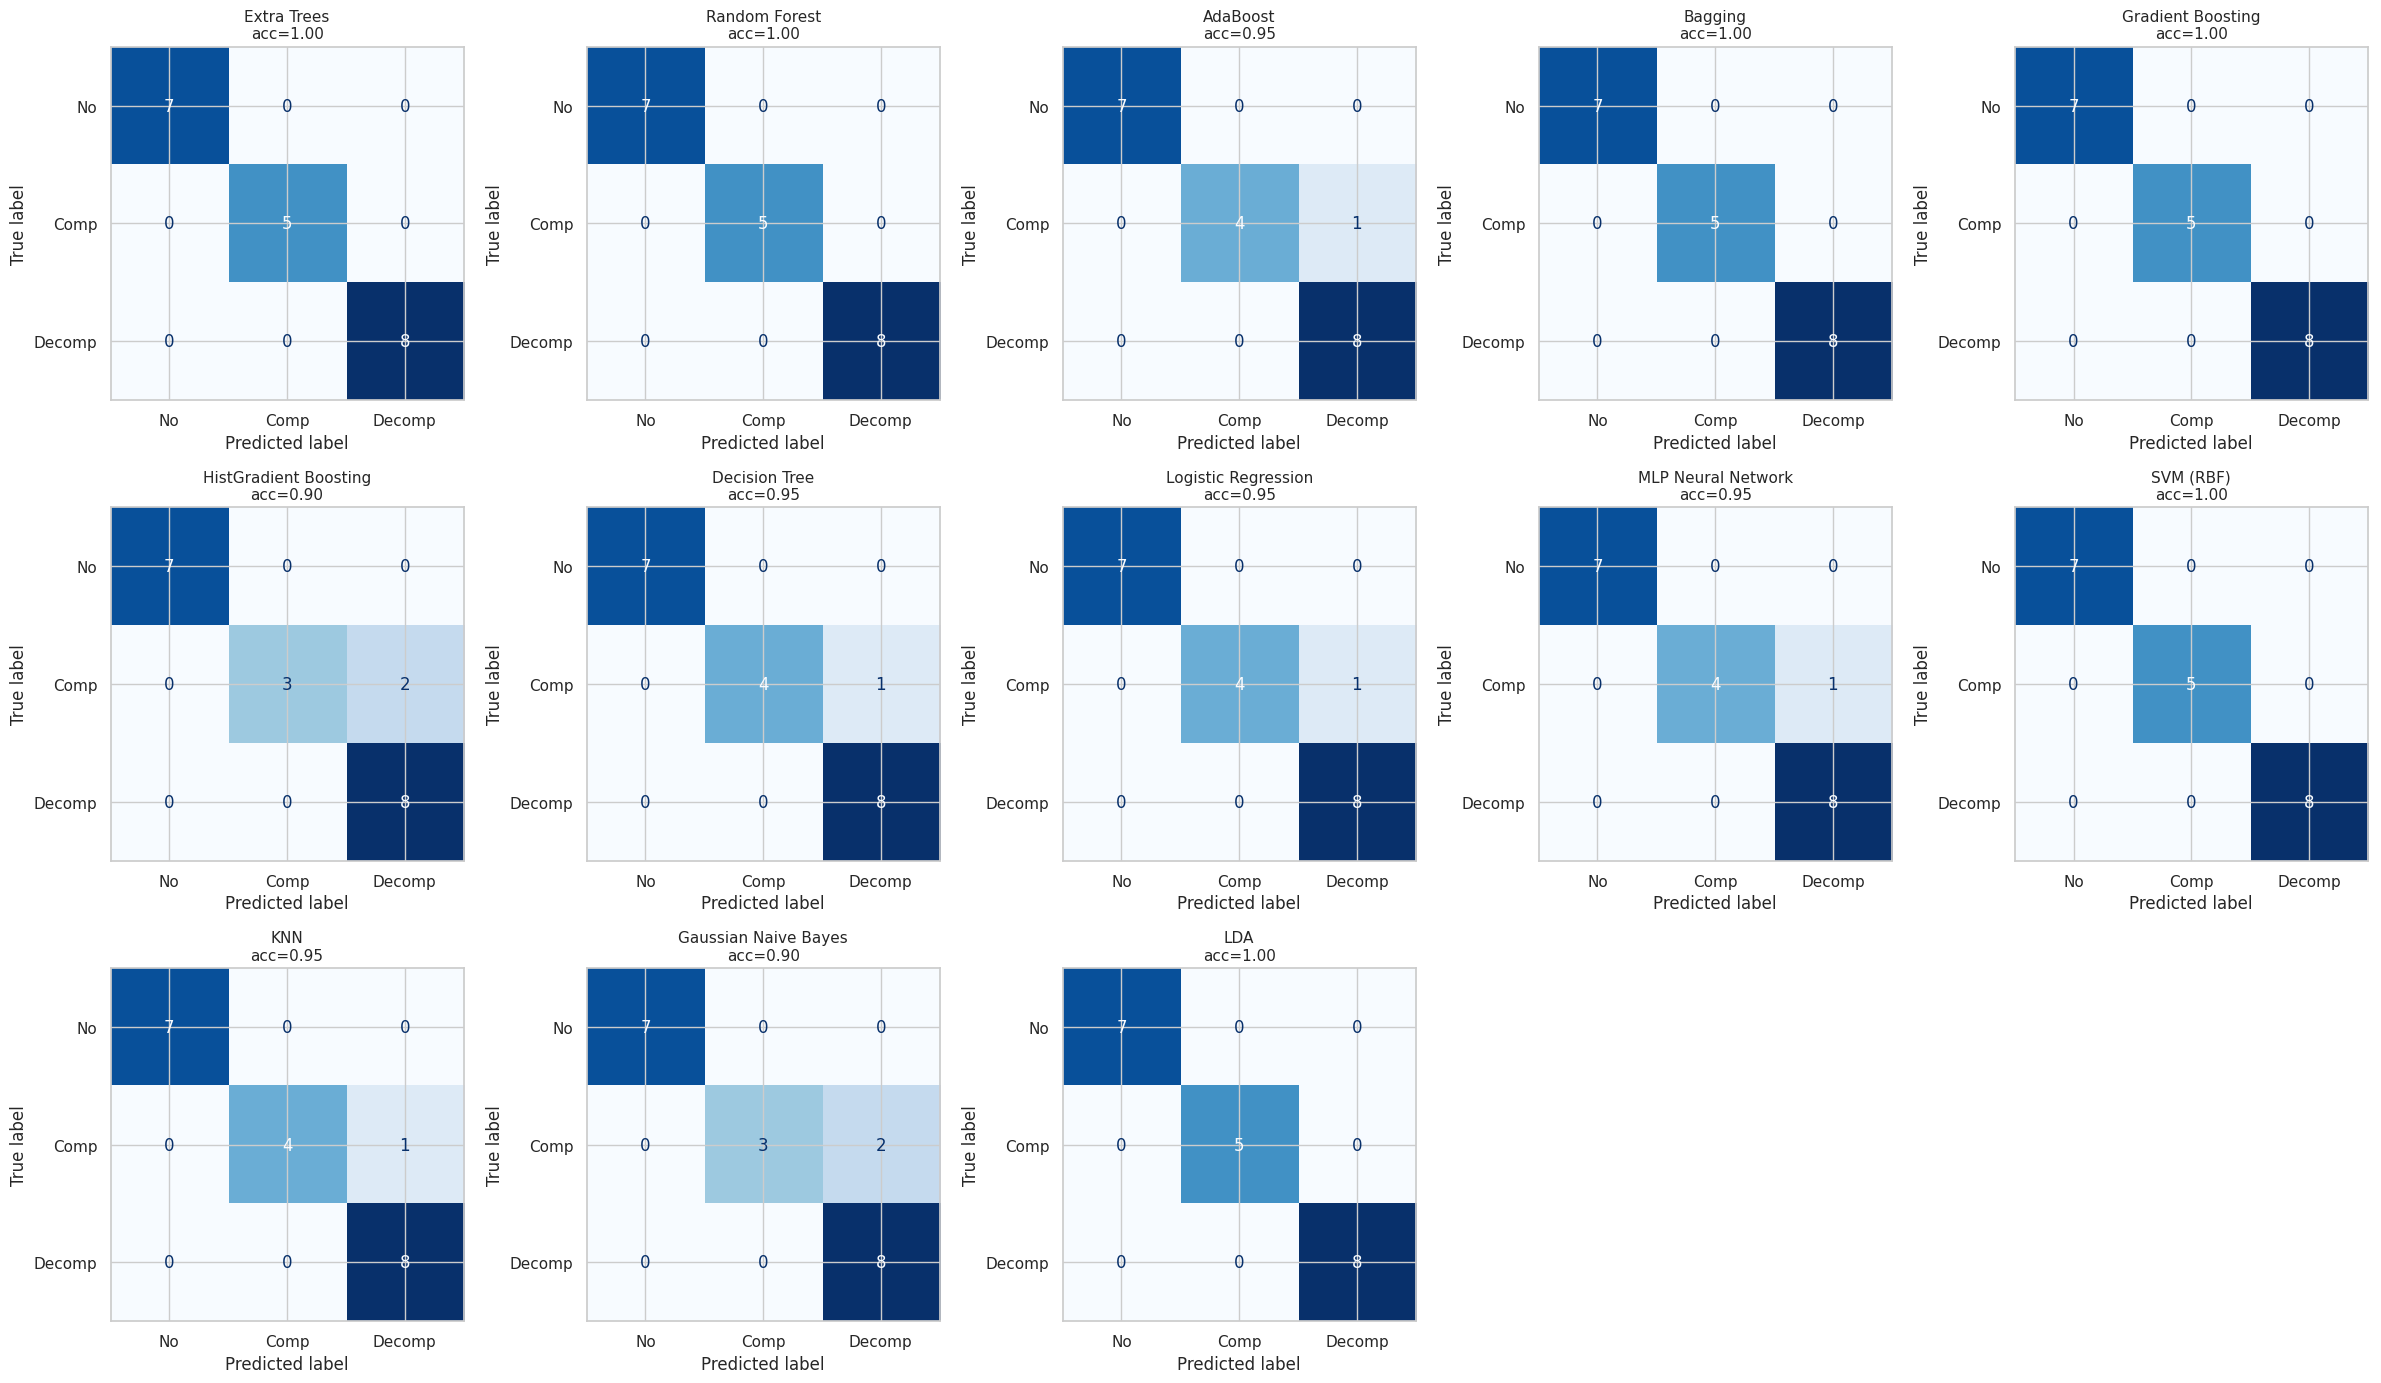

In [17]:
names = list(resA["test"].index)
fig, axes = plt.subplots(3, 5, figsize=(24, 14))
for a, n in zip(axes.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(y_test, resA["preds"][n], display_labels=["No","Comp","Decomp"],
                                            cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"{n}\nacc={accuracy_score(y_test, resA['preds'][n]):.2f}", fontsize=11)
for a in axes.ravel()[len(names):]: a.axis("off")
plt.tight_layout(); plt.show()

### 6.4 ROC curves (one-vs-rest, macro-average) — top 5 models by CV F1

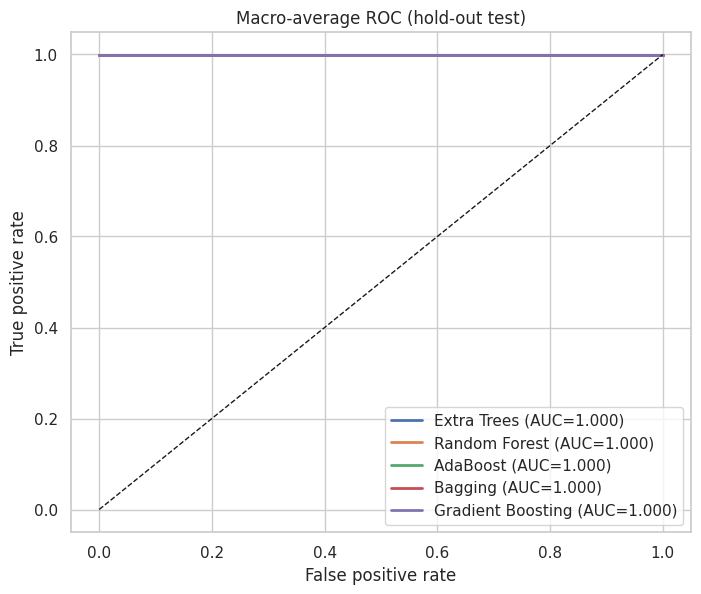

In [18]:
y_bin = label_binarize(y_test, classes=[0, 1, 2])
top5 = list(resA["cv"].index[:5])
fig, ax = plt.subplots(figsize=(8, 6.5))
for n in top5:
    pr = resA["probas"][n]
    fpr_all = np.unique(np.concatenate([roc_curve(y_bin[:, i], pr[:, i])[0] for i in range(3)]))
    mean_tpr = np.mean([np.interp(fpr_all, *roc_curve(y_bin[:, i], pr[:, i])[:2]) for i in range(3)], axis=0)
    ax.plot(fpr_all, mean_tpr, lw=2, label=f"{n} (AUC={auc(fpr_all, mean_tpr):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="Macro-average ROC (hold-out test)")
ax.legend(loc="lower right"); plt.show()

### 6.5 Best model — detailed report

Best model by cross-validated macro-F1: Extra Trees
CV F1 = 0.9969 ± 0.0153

               precision    recall  f1-score   support

 No_Cirrhosis      1.000     1.000     1.000         7
  Compensated      1.000     1.000     1.000         5
Decompensated      1.000     1.000     1.000         8

     accuracy                          1.000        20
    macro avg      1.000     1.000     1.000        20
 weighted avg      1.000     1.000     1.000        20



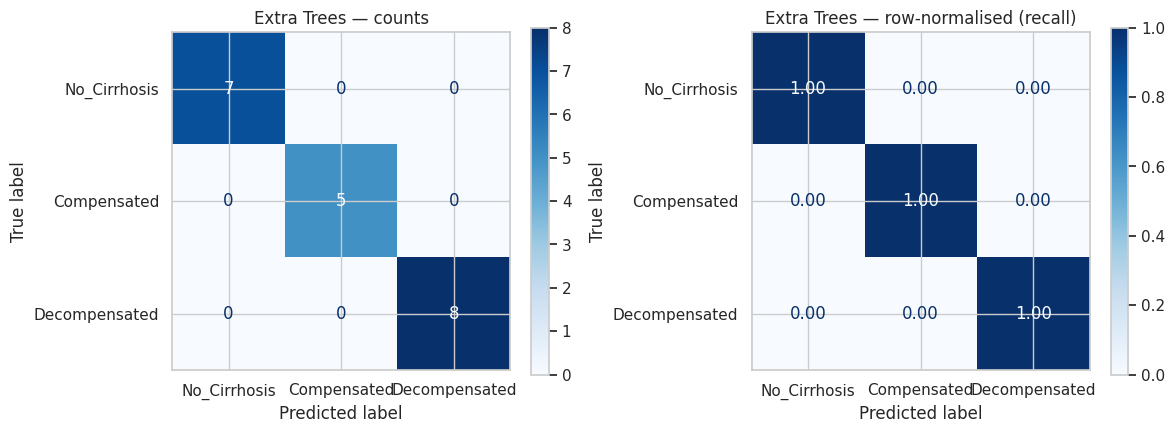

In [19]:
best_name = resA["cv"].index[0]
print("Best model by cross-validated macro-F1:", best_name)
print(f"CV F1 = {resA['cv'].loc[best_name,'CV f1']:.4f} ± {resA['cv'].loc[best_name,'CV f1 std']:.4f}\n")
print(classification_report(y_test, resA["preds"][best_name], target_names=class_names, digits=3, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, resA["preds"][best_name], display_labels=class_names, cmap="Blues", ax=ax[0])
ConfusionMatrixDisplay.from_predictions(y_test, resA["preds"][best_name], display_labels=class_names, cmap="Blues",
                                        normalize="true", values_format=".2f", ax=ax[1])
ax[0].set_title(f"{best_name} — counts"); ax[1].set_title(f"{best_name} — row-normalised (recall)")
plt.tight_layout(); plt.show()

### 6.6 Feature importance

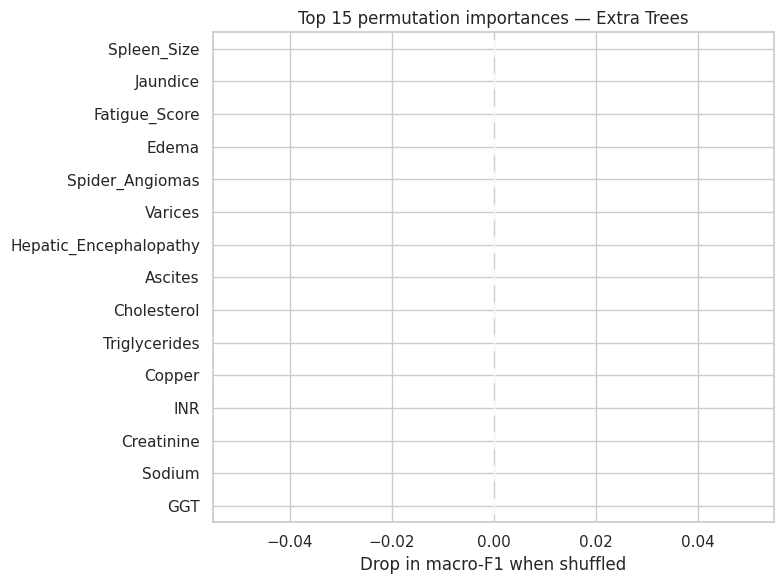

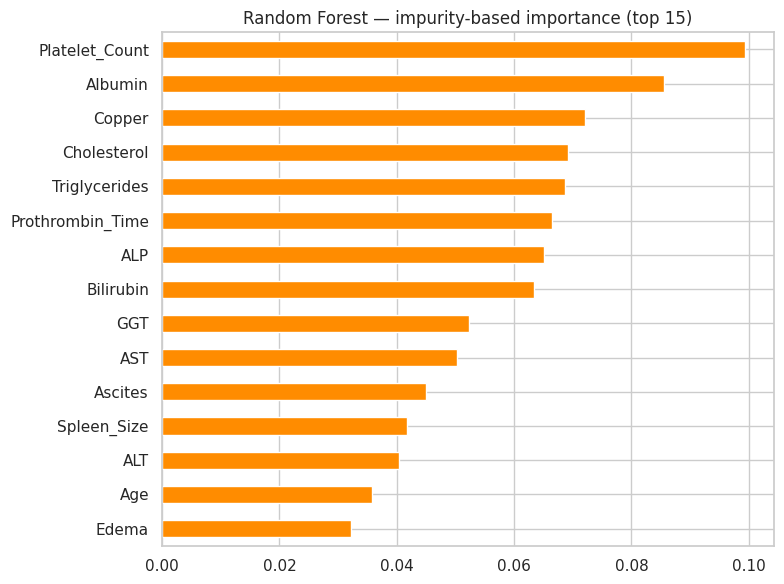

In [20]:
# Permutation importance on the training set (more stable than the 20-sample test set) for the best model.
Xtr_A = X_train[FEATURES_A]
pi = permutation_importance(resA["fitted"][best_name], Xtr_A, y_train, n_repeats=20,
                            scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES_A).sort_values(ascending=True).tail(15)
err = pd.Series(pi.importances_std, index=FEATURES_A)[imp.index]
imp.plot.barh(xerr=err, figsize=(8, 6), color="teal")
plt.title(f"Top 15 permutation importances — {best_name}"); plt.xlabel("Drop in macro-F1 when shuffled")
plt.tight_layout(); plt.show()

# Tree-ensemble impurity importance for comparison
rf = resA["fitted"]["Random Forest"].named_steps["clf"]
pd.Series(rf.feature_importances_, index=FEATURES_A).sort_values().tail(15).plot.barh(figsize=(8, 6), color="darkorange")
plt.title("Random Forest — impurity-based importance (top 15)"); plt.tight_layout(); plt.show()

## 7. Cross-validation stability of all models

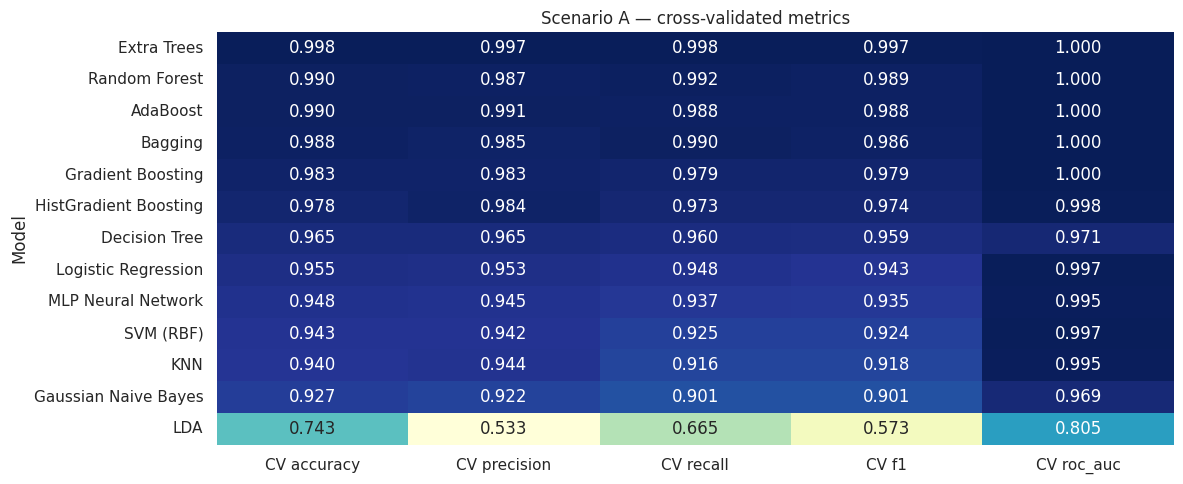

In [21]:
plt.figure(figsize=(12, 5))
plot_df = resA["cv"][["CV accuracy","CV precision","CV recall","CV f1","CV roc_auc"]]
sns.heatmap(plot_df, annot=True, fmt=".3f", cmap="YlGnBu", cbar=False)
plt.title("Scenario A — cross-validated metrics"); plt.tight_layout(); plt.show()

## 8. Sensitivity analysis — Scenario B (adding Fibrosis_Stage, MELD_Score, Child_Pugh_Class)

To test the leakage concern empirically, the identical pipeline is re-run with the three severity scores included.

In [22]:
resB = run_experiment(FEATURES_B, "Scenario B (with severity scores)")
cmp = pd.DataFrame({
    "CV F1 — A (no scores)":   resA["cv"]["CV f1"],
    "CV F1 — B (with scores)": resB["cv"]["CV f1"],
    "Test Acc — A": resA["test"]["Accuracy"],
    "Test Acc — B": resB["test"]["Accuracy"],
})
cmp["CV F1 gain from scores"] = cmp["CV F1 — B (with scores)"] - cmp["CV F1 — A (no scores)"]
cmp.sort_values("CV F1 — B (with scores)", ascending=False).round(4)

,CV F1 — A (no scores),CV F1 — B (with scores),Test Acc — A,Test Acc — B,CV F1 gain from scores
Model,,,,,
Extra Trees,0.9969,1.0000,1.00,1.00,0.0031
AdaBoost,0.9880,0.9914,0.95,0.95,0.0034
Bagging,0.9861,0.9887,1.00,1.00,0.0026
Random Forest,0.9887,0.9887,1.00,1.00,0.0000
Decision Tree,0.9593,0.9797,0.95,0.95,0.0204
Gradient Boosting,0.9785,0.9760,1.00,1.00,-0.0025
HistGradient Boosting,0.9735,0.9735,0.90,0.90,0.0000
Logistic Regression,0.9432,0.9703,0.95,0.95,0.0270
MLP Neural Network,0.9346,0.9511,0.95,0.95,0.0165


Scenario B — full hold-out metrics


,Accuracy,Balanced Acc,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (OvR),MCC,Cohen Kappa
Model,,,,,,,,,,,
Extra Trees,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
AdaBoost,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,1.0000,0.9265,0.9228
Bagging,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
Decision Tree,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,0.9528,0.9265,0.9228
Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
HistGradient Boosting,0.9000,0.8667,0.9333,0.8667,0.8796,0.9200,0.9000,0.8931,1.0000,0.8578,0.8438
Logistic Regression,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,0.9956,0.9265,0.9228
MLP Neural Network,0.9500,0.9333,0.9630,0.9333,0.9434,0.9556,0.9500,0.9487,1.0000,0.9265,0.9228


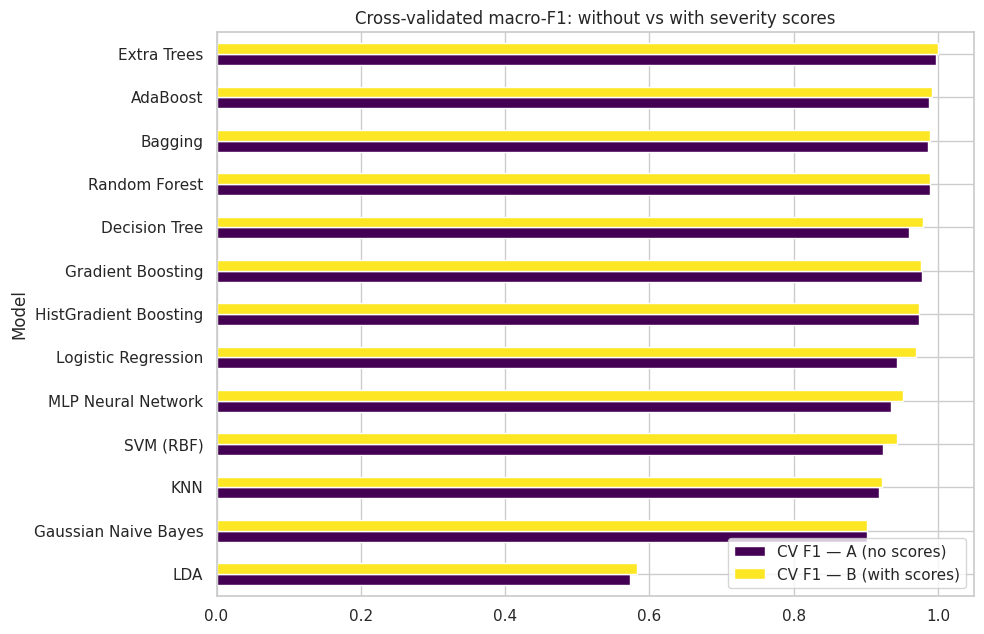

In [23]:
print("Scenario B — full hold-out metrics")
display(resB["test"].round(4).style.background_gradient(cmap="YlGn").format("{:.4f}"))
c = cmp.sort_values("CV F1 — B (with scores)")[["CV F1 — A (no scores)", "CV F1 — B (with scores)"]]
c.plot.barh(figsize=(10, 6.5), colormap="viridis"); plt.xlim(0, 1.05)
plt.title("Cross-validated macro-F1: without vs with severity scores"); plt.tight_layout(); plt.show()

## 9. Final summary

In [24]:
summary = pd.DataFrame({
    "Scenario A — CV Accuracy": resA["cv"]["CV accuracy"],
    "Scenario A — CV F1": resA["cv"]["CV f1"],
    "Scenario A — Test Accuracy": resA["test"]["Accuracy"],
    "Scenario A — Test F1": resA["test"]["F1 (macro)"],
    "Scenario B — CV F1": resB["cv"]["CV f1"],
    "Scenario B — Test F1": resB["test"]["F1 (macro)"],
}).sort_values("Scenario A — CV F1", ascending=False)
display(summary.round(4))
print(f"Best model — Scenario A: {resA['cv'].index[0]} (CV F1 = {resA['cv']['CV f1'].iloc[0]:.3f})")
print(f"Best model — Scenario B: {resB['cv'].index[0]} (CV F1 = {resB['cv']['CV f1'].iloc[0]:.3f})")

,Scenario A — CV Accuracy,Scenario A — CV F1,Scenario A — Test Accuracy,Scenario A — Test F1,Scenario B — CV F1,Scenario B — Test F1
Model,,,,,,
Extra Trees,0.9975,0.9969,1.00,1.0000,1.0000,1.0000
Random Forest,0.9900,0.9887,1.00,1.0000,0.9887,1.0000
AdaBoost,0.9900,0.9880,0.95,0.9434,0.9914,0.9434
Bagging,0.9875,0.9861,1.00,1.0000,0.9887,1.0000
Gradient Boosting,0.9825,0.9785,1.00,1.0000,0.9760,1.0000
HistGradient Boosting,0.9775,0.9735,0.90,0.8796,0.9735,0.8796
Decision Tree,0.9650,0.9593,0.95,0.9434,0.9797,0.9434
Logistic Regression,0.9550,0.9432,0.95,0.9434,0.9703,0.9434
MLP Neural Network,0.9475,0.9346,0.95,0.9434,0.9511,0.9434


Best model — Scenario A: Extra Trees (CV F1 = 0.997)
Best model — Scenario B: Extra Trees (CV F1 = 1.000)
